# MUTAG ≤14 atoms — Kernel Classification Benchmark

Compare a structure-free classical kernel, a graph kernel (Weisfeiler-Lehman), and a
Pulser-simulated Quantum Evolution Kernel on the 53 MUTAG molecules with at most 14 atoms.

In [ ]:
!pip install pulser

In [ ]:
!pip install quantum-evolution-kernel

  Using cached quantum_evolution_kernel-0.3.4-py3-none-any.whl.metadata (5.8 kB)
  Using cached emu_mps-2.2.1-py3-none-any.whl.metadata (3.6 kB)
  Using cached rdkit-2026.3.6-cp312-cp312-manylinux_2_28_x86_64.whl.metadata (3.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 891.8 kB/s eta 0:00:00
INFO: pip is looking at multiple versions of pulser to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of pulser to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
INFO: pip is looking at multiple versions of pasqal-cloud to determine which version is compatible with other requirements. This could take a while.
INFO:

In [ ]:
from pathlib import Path
import ast
import hashlib
import time
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import rbf_kernel
from scipy.stats import wilcoxon

RANDOM_STATE = 42
ATOM_LABELS = ["C", "N", "O", "F", "I", "Cl", "Br"]

def parse_cell(x):
    return ast.literal_eval(x) if isinstance(x, str) else x

## 1. Load data

In [ ]:
df_full = pd.read_json("hf://datasets/graphs-datasets/MUTAG/full.jsonl", lines=True)
df_full["y"] = df_full["y"].map(lambda x: int(parse_cell(x)[0]))

In [ ]:
df_full

,edge_index,node_feat,edge_attr,y,num_nodes
0,"[[0, 0, 1, 1, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 6,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",1,17
1,"[[0, 0, 1, 1, 2, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",0,13
2,"[[0, 0, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 5, 5, 6,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",0,13
3,"[[0, 0, 1, 1, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 6,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",1,19
4,"[[0, 0, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 5, 5, 5,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",0,11
...,...,...,...,...,...
183,"[[0, 0, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 5, 5, 6,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",1,22
184,"[[0, 0, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 5, 5, 5,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",0,13
185,"[[0, 0, 1, 1, 2, 2, 2, 3, 3, 3, 4, 4, 5, 5, 5,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",0,12
186,"[[0, 0, 1, 1, 2, 2, 3, 3, 3, 4, 4, 4, 5, 5, 6,...","[[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 0....","[[1.0, 0.0, 0.0, 0.0], [1.0, 0.0, 0.0, 0.0], [...",1,21


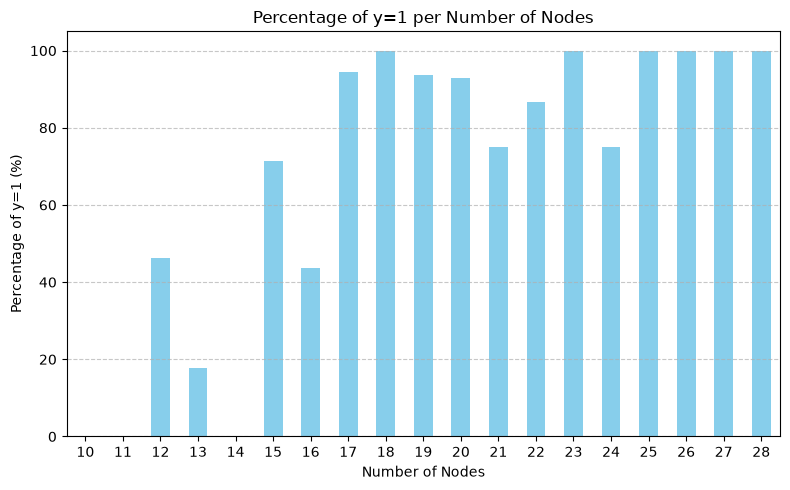

In [ ]:
# Calculate the percentage of 'y=1' for each 'num_nodes'
percentage_y1_per_num_nodes = df_full.groupby('num_nodes')['y'].mean() * 100

# Create a bar chart
plt.figure(figsize=(8, 5))
percentage_y1_per_num_nodes.plot(kind='bar', color='skyblue')
plt.title('Percentage of y=1 per Number of Nodes')
plt.xlabel('Number of Nodes')
plt.ylabel('Percentage of y=1 (%)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
print("Class counts:")
print(df_full["y"].value_counts().sort_index().to_string())

Class counts:
y
0     63
1    125


In [ ]:
print(pd.crosstab(df_full["num_nodes"], df_full["y"]))

y           0   1
num_nodes        
10          2   0
11         14   0
12          7   6
13         14   3
14          7   0
15          2   5
16          9   7
17          1  17
18          0   4
19          1  15
20          1  13
21          2   6
22          2  13
23          0  18
24          1   3
25          0   6
26          0   5
27          0   1
28          0   3


In [ ]:
node_vectors = [tuple(v) for row in df_full["node_feat"] for v in np.asarray(parse_cell(row), dtype=float)]
edge_vectors = [tuple(v) for row in df_full["edge_attr"] for v in np.asarray(parse_cell(row), dtype=float)]
print("Unique atom feature vectors:")
print(pd.Series(node_vectors).value_counts().to_string())
print()
print("Unique bond feature vectors:")
print(pd.Series(edge_vectors).value_counts().to_string())

Unique atom feature vectors:
(1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0)    2395
(0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0)     593
(0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0)     345
(0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0)      23
(0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0)      12
(0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0)       2
(0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0)       1

Unique bond feature vectors:
(1.0, 0.0, 0.0, 0.0)    4708
(0.0, 1.0, 0.0, 0.0)    2008
(0.0, 0.0, 1.0, 0.0)     724
(0.0, 0.0, 0.0, 1.0)       2


# Apply the ≤14-atom restriction

In [ ]:
df = pd.read_json("hf://datasets/graphs-datasets/MUTAG/full.jsonl", lines=True)
data = df.loc[df["num_nodes"] <= 14].copy().reset_index(drop=True)
data["y"] = data["y"].map(lambda x: int(parse_cell(x)[0]))

print("Reduced dataset shape:", data.shape)
print()
print("Class counts:")
print(data["y"].value_counts().sort_index().to_string())
print()
print("Class proportions:")
print(data["y"].value_counts(normalize=True).sort_index().round(3).to_string())
print()
print("Number of atoms:")
print(data["num_nodes"].describe().round(2).to_string())

Reduced dataset shape: (53, 5)

Class counts:
y
0    44
1     9

Class proportions:
y
0    0.83
1    0.17

Number of atoms:
count    53.00
mean     12.25
std       1.11
min      10.00
25%      11.00
50%      12.00
75%      13.00
max      14.00


**Constraint this sets:** 53 graphs (down from 188 in original dataset), minority class = 9. A random split can easily put 1-2
positives in test; accuracy alone would be misleading (a majority-class predictor already scores
83%). We use balanced accuracy / ROC-AUC, class-weighted SVMs, and repeated stratified k-fold
throughout. Dataset is extremely small. Machine Learning would not normally be a consideration with such little data.

In [ ]:
# Always predicting 'y=0' gives 83% accuracy.
# Balanced accuracy (Recall) = true positives/(true positives + false negatives)
# Averages accuracy PER CLASS

In [ ]:
print(pd.crosstab(data["num_nodes"], data["y"]))

y           0  1
num_nodes       
10          2  0
11         14  0
12          7  6
13         14  3
14          7  0


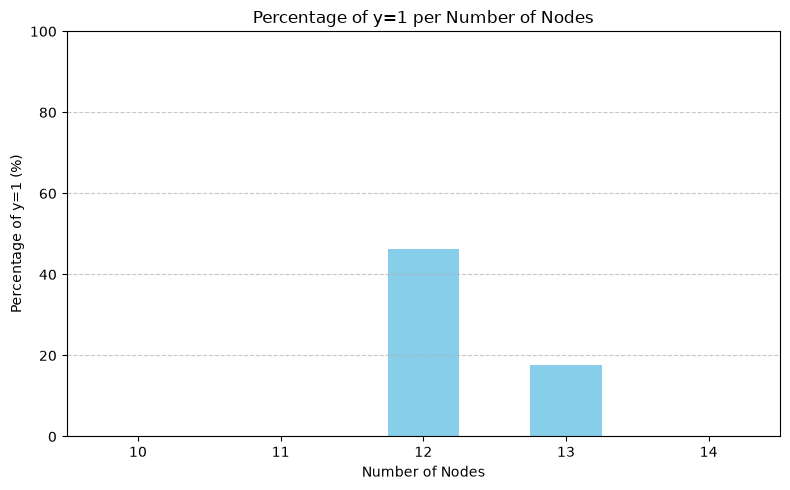

In [ ]:
# Calculate the percentage of 'y=1' for each 'num_nodes'
percentage_y1_per_num_nodes = data.groupby('num_nodes')['y'].mean() * 100

# Create a bar chart
plt.figure(figsize=(8, 5))
percentage_y1_per_num_nodes.plot(kind='bar', color='skyblue')
plt.title('Percentage of y=1 per Number of Nodes')
plt.xlabel('Number of Nodes')
plt.ylabel('Percentage of y=1 (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Positives only occur at 12-13 atoms in this subset. This should be noted.

## 2. Decode atom/bond labels and build labelled graphs

In [ ]:
node_vectors = [tuple(v) for row in data["node_feat"] for v in np.asarray(parse_cell(row), dtype=float)]
edge_vectors = [tuple(v) for row in data["edge_attr"] for v in np.asarray(parse_cell(row), dtype=float)]
print("Unique atom feature vectors:")
print(pd.Series(node_vectors).value_counts().to_string())
print()
print("Unique bond feature vectors:")
print(pd.Series(edge_vectors).value_counts().to_string())

Unique atom feature vectors:
(1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0)    393
(0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0)    135
(0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0)    104
(0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0)      8
(0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0)      8
(0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0)      1

Unique bond feature vectors:
(1.0, 0.0, 0.0, 0.0)    582
(0.0, 1.0, 0.0, 0.0)    534
(0.0, 0.0, 1.0, 0.0)    232


In [ ]:
# ATOM_LABELS = ["C", "N", "O", "F", "I", "Cl", "Br"]
# No Iodine present in reduced dataset (Only 1 in full dataset)
# No triple bonds present in reduced dataset (only 2 in full dataset)

# Create graph objects

In [ ]:
def row_to_graph(row):
    G = nx.Graph()
    node_features = np.asarray(parse_cell(row["node_feat"]), dtype=float)
    edge_index = np.asarray(parse_cell(row["edge_index"]), dtype=int)
    edge_features = np.asarray(parse_cell(row["edge_attr"]), dtype=float)
    for i, feat in enumerate(node_features):
        G.add_node(i, atom=ATOM_LABELS[int(np.argmax(feat))])
    for k, (u, v) in enumerate(edge_index.T):
        G.add_edge(int(u), int(v), bond=int(np.argmax(edge_features[k])))
        #G.add_edge(u, v, bond=BOND_LABELS[int(np.argmax(edge_features[k]))])
    return G

graphs = [row_to_graph(row) for _, row in data.iterrows()]
print("Number of graphs:", len(graphs))
print("First graph:", graphs[0].number_of_nodes(), "nodes,", graphs[0].number_of_edges(), "edges")
print("First graph atom labels:", dict(graphs[0].nodes(data="atom")))

Number of graphs: 53
First graph: 13 nodes, 14 edges
First graph atom labels: {0: 'C', 1: 'C', 2: 'C', 3: 'C', 4: 'C', 5: 'C', 6: 'N', 7: 'C', 8: 'C', 9: 'C', 10: 'N', 11: 'O', 12: 'O'}


## 3. Graph audit, composition by class, and duplicate check

In [ ]:
data["n_edges"] = [G.number_of_edges() for G in graphs]
data["density"] = [G.number_of_edges() / (G.number_of_nodes()*(G.number_of_nodes()-1)/2) for G in graphs]

atom_counts = np.array([np.bincount([ATOM_LABELS.index(G.nodes[i]["atom"]) for i in G.nodes], minlength=len(ATOM_LABELS)) for G in graphs])
atom_count_df = pd.DataFrame(atom_counts, columns=[f"n_{a}" for a in ATOM_LABELS])
n_bond_types = max(max([d["bond"] for _, _, d in G.edges(data=True)], default=-1) for G in graphs) + 1
bond_counts = np.array([np.bincount([d["bond"] for _, _, d in G.edges(data=True)], minlength=n_bond_types) for G in graphs])
bond_count_df = pd.DataFrame(bond_counts, columns=[f"bond_type_{i}" for i in range(n_bond_types)])
molecule_features = pd.concat([data[["y","num_nodes","n_edges","density"]].reset_index(drop=True), atom_count_df, bond_count_df], axis=1)

print(data.groupby("y")[["num_nodes","n_edges","density"]].agg(["mean","std"]).round(3))
print()
print("Correlation with y:")
print(molecule_features.corr(numeric_only=True)["y"].drop("y").sort_values().round(3).to_string())

  num_nodes        n_edges        density       
       mean    std    mean    std    mean    std
y                                               
0    12.227  1.198  12.682  1.552   0.186  0.017
1    12.333  0.500  12.889  0.601   0.185  0.013

Correlation with y:
bond_type_0   -0.194
n_C           -0.097
n_Br          -0.063
n_F           -0.040
n_Cl          -0.040
density       -0.026
num_nodes      0.036
n_edges        0.055
n_N            0.078
bond_type_1    0.171
n_O            0.185
bond_type_2    0.240
n_I              NaN


In [ ]:
# No strong correlations

In [ ]:
def make_hashable(obj):
    return tuple(make_hashable(x) for x in obj) if isinstance(obj, list) else obj

data_for_dedup = data.copy()
for col in ["edge_index", "node_feat", "edge_attr"]:
    data_for_dedup[col] = data_for_dedup[col].apply(lambda s: make_hashable(parse_cell(s)))
exact_dup = data_for_dedup.duplicated(subset=["edge_index","node_feat","edge_attr","y"]).sum()

node_match = nx.algorithms.isomorphism.categorical_node_match("atom", None)
edge_match = nx.algorithms.isomorphism.categorical_edge_match("bond", None)
dup_pairs = [(i,j) for i in range(len(graphs)) for j in range(i)
             if nx.is_isomorphic(graphs[i], graphs[j], node_match=node_match, edge_match=edge_match)]
print("Exact duplicate rows:", exact_dup)
print("Label-preserving isomorphic duplicate pairs:", len(dup_pairs))

Exact duplicate rows: 0
Label-preserving isomorphic duplicate pairs: 0


## 4. Trivial baseline: bag-of-atoms kernel

Uses only the counts of C/N/O/F/I/Cl/Br per molecule: no bonds, no topology at all. The purpose of this model is to show the importance of using graphs. The connections between nodes include important information

In [ ]:
def normalize_kernel(K):
    K = np.asarray(K, dtype=float)
    d = np.sqrt(np.clip(np.diag(K), 1e-12, None))
    return K / np.outer(d, d)

def _median_gamma(X):
    X = np.asarray(X, dtype=float)
    sq = np.sum((X[:, None, :] - X[None, :, :]) ** 2, axis=-1)
    med = np.median(sq[sq > 0]) if np.any(sq > 0) else 1.0
    return 1.0 / med

def rbf_kernel_train_test(X_tr, X_te, gamma=None):
    X_tr, X_te = np.asarray(X_tr, float), np.asarray(X_te, float)
    if gamma is None:
        gamma = _median_gamma(X_tr)
    K_tr_raw = rbf_kernel(X_tr, X_tr, gamma=gamma)
    d_tr = np.sqrt(np.clip(np.diag(K_tr_raw), 1e-12, None))
    K_tr = K_tr_raw / np.outer(d_tr, d_tr)
    K_te_raw = rbf_kernel(X_te, X_tr, gamma=gamma)
    K_te_self_raw = rbf_kernel(X_te, X_te, gamma=gamma)
    d_te = np.sqrt(np.clip(np.diag(K_te_self_raw), 1e-12, None))
    K_te = K_te_raw / np.outer(d_te, d_tr)
    return K_tr, K_te

def make_bag_of_atoms_builder(X_bag):
    X_bag = np.asarray(X_bag, dtype=float)
    def builder(tr, te):
        scaler = StandardScaler().fit(X_bag[tr])
        return rbf_kernel_train_test(scaler.transform(X_bag[tr]), scaler.transform(X_bag[te]), gamma=None)
    return builder

bag_builder = make_bag_of_atoms_builder(atom_count_df.to_numpy(dtype=float))
print("bag-of-atoms feature shape:", atom_count_df.shape)

bag-of-atoms feature shape: (53, 7)


In [ ]:
# Uses only atom type counts per molecule, no connections

## 5. Weisfeiler-Lehman graph kernel (edge-aware, hashed signatures)

At iteration 0 each node is labelled by its atom. At each subsequent iteration a node's new label
hashes together its current label and the sorted multiset of `(bond type, neighbour label)` pairs so both atom identity and bond order propagate into the feature space.

In [ ]:
# neighborhood based

In [ ]:
def _hash_signature(sig, digest_size=8):
    return hashlib.blake2b(sig.encode("utf-8"), digest_size=digest_size).hexdigest()

def wl_features_hashed(G, h=2, digest_size=8):
    labels = {v: G.nodes[v]["atom"] for v in G}
    features = {}
    for lab in labels.values():
        features[lab] = features.get(lab, 0) + 1
    for _ in range(h):
        new_labels = {}
        for v in G.nodes:
            neighborhood = tuple(sorted((G.edges[v, u]["bond"], labels[u]) for u in G.neighbors(v)))
            new_labels[v] = _hash_signature(repr((labels[v], neighborhood)), digest_size)
        labels = new_labels
        for lab in labels.values():
            features[lab] = features.get(lab, 0) + 1
    return features

def wl_feature_matrix_hashed(graphs, h=2, digest_size=8):
    dicts = [wl_features_hashed(G, h=h, digest_size=digest_size) for G in graphs]
    vocab = sorted({f for d in dicts for f in d})
    col = {f: j for j, f in enumerate(vocab)}
    X = np.zeros((len(graphs), len(vocab)))
    for i, d in enumerate(dicts):
        for f, c in d.items():
            X[i, col[f]] = c
    return X, vocab

def make_wl_builder(graphs, h=2, digest_size=8):
    X_wl, vocab = wl_feature_matrix_hashed(graphs, h=h, digest_size=digest_size)
    X_wl = X_wl.astype(float)
    def builder(tr, te):
        K_tr_raw = X_wl[tr] @ X_wl[tr].T
        d_tr = np.sqrt(np.clip(np.diag(K_tr_raw), 1e-12, None))
        K_tr = K_tr_raw / np.outer(d_tr, d_tr)
        K_te_raw = X_wl[te] @ X_wl[tr].T
        d_te = np.sqrt(np.clip(np.sum(X_wl[te] ** 2, axis=1), 1e-12, None))
        K_te = K_te_raw / np.outer(d_te, d_tr)
        return K_tr, K_te
    return builder, X_wl, vocab

wl_builder, X_wl, wl_vocab = make_wl_builder(graphs, h=2, digest_size=8)
print("WL feature matrix:", X_wl.shape)

WL feature matrix: (53, 220)



## 6. Quantum evolution kernel, simulated with Pulser

In this implementation the **graph connectivity** is used to construct the geometry.

In [ ]:
# label-aware model had worse result

In [ ]:
import dataclasses
from pulser import Pulse, Sequence, Register
from pulser.waveforms import BlackmanWaveform, RampWaveform
from pulser.devices import AnalogDevice
from pulser_simulation import QutipEmulator
from scipy.spatial.distance import pdist, squareform

C6 = AnalogDevice.interaction_coeff
OMEGA_MAX = 2*np.pi*1.0                  # rad/us (1 MHz Rabi)
R_B = (C6/OMEGA_MAX)**(1/6)              # blockade radius, um
EDGE_TARGET_UM, MIN_ATOM_DIST_UM = 6.0, 5.0
PULSE_DURATION_NS, DET_MAX = 660, OMEGA_MAX*2.0

SIM_DEVICE = dataclasses.replace(AnalogDevice.to_virtual(), min_atom_distance=0.0, max_radial_distance=None)
print("blockade radius R_b =", round(R_B, 2), "um")

def embed_graph(G, seed=0):
    pos = nx.spring_layout(G, seed=seed, dim=2, k=1.2/np.sqrt(max(G.number_of_nodes(),1)))
    nodes = list(G.nodes()); coords = np.array([pos[n] for n in nodes])
    elens = [np.linalg.norm(coords[nodes.index(u)]-coords[nodes.index(v)]) for u,v in G.edges()]
    coords *= EDGE_TARGET_UM / (np.median(elens) if elens else 1.0)
    D = squareform(pdist(coords)); np.fill_diagonal(D, np.inf)
    if D.min() < MIN_ATOM_DIST_UM*1.02:
        coords *= (MIN_ATOM_DIST_UM*1.02) / D.min()
    return coords - coords.mean(axis=0)

def unit_disk_fidelity(G, coords):
    nodes = list(G.nodes()); idx = {n:i for i,n in enumerate(nodes)}
    D = squareform(pdist(coords)); correct = total = 0
    for i,u in enumerate(nodes):
        for v in nodes[i+1:]:
            total += 1
            correct += (G.has_edge(u,v) == (D[idx[u],idx[v]] <= R_B))
    return correct/total if total else 1.0

def best_embedding(G, n_restarts=8):
    best_c, best_f = None, -1
    for s in range(n_restarts):
        c = embed_graph(G, seed=s); f = unit_disk_fidelity(G, c)
        if f > best_f: best_c, best_f = c, f
    return best_c, best_f

def build_sequence(coords):
    reg = Register({f"q{i}": c for i,c in enumerate(coords)})
    seq = Sequence(reg, SIM_DEVICE)
    seq.declare_channel("ising", "rydberg_global")
    seq.add(Pulse(BlackmanWaveform(PULSE_DURATION_NS, np.pi),
                  RampWaveform(PULSE_DURATION_NS, -DET_MAX, DET_MAX), 0), "ising")
    return seq

def excitation_distribution(G, n_restarts=8):
    t0 = time.time()
    coords, fid = best_embedding(G, n_restarts=n_restarts)
    sim = QutipEmulator.from_sequence(build_sequence(coords), sampling_rate=0.5)
    final = sim.run().get_final_state()
    probs = np.abs(final.full().flatten())**2
    n = G.number_of_nodes()
    k_of_index = np.array([bin(i).count("1") for i in range(2**n)])
    p = np.zeros(n+1); np.add.at(p, k_of_index, probs); p /= p.sum()
    return p, fid, time.time()-t0

def js_divergence(p, q):
    n = max(len(p), len(q)); pp = np.zeros(n); qq = np.zeros(n)
    pp[:len(p)] = p; qq[:len(q)] = q; m = 0.5*(pp+qq)
    kl = lambda a,b: np.sum(a[a>0]*np.log2(a[a>0]/b[a>0]))
    return 0.5*kl(pp,m) + 0.5*kl(qq,m)

blockade radius R_b = 7.19 um


In [ ]:

t0 = time.time()
qfeat = [excitation_distribution(G, n_restarts=8) for G in graphs]
dists, fids, runtimes = zip(*qfeat)
total = time.time() - t0
print(f"simulated {len(graphs)} registers in {total:.1f}s total ({total/len(graphs):.2f}s/molecule)")
print(f"unit-disk embedding fidelity: mean={np.mean(fids):.3f} min={np.min(fids):.3f} max={np.max(fids):.3f}")
print(f"per-molecule simulation time: mean={np.mean(runtimes):.2f}s median={np.median(runtimes):.2f}s max={np.max(runtimes):.2f}s")

n = len(dists)
JS = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        JS[i, j] = JS[j, i] = js_divergence(dists[i], dists[j])

print("The JS matrix is computed without labels. Its scale parameter sigma is selected inside each training fold below.")


simulated 53 registers in 24.4s total (0.46s/molecule)
unit-disk embedding fidelity: mean=0.956 min=0.924 max=1.000
per-molecule simulation time: mean=0.46s median=0.32s max=1.24s
The JS matrix is computed without labels. Its scale parameter sigma is selected inside each training fold below.



## 7. Nested cross-validated comparison

Repeated stratified 5-fold CV (10 repeats) is used with identical outer folds for all three methods. `C` is selected by an inner stratified CV on each outer training fold only, and `class_weight="balanced"` is used throughout because the reduced dataset contains only 9 minority-class molecules.

We report balanced accuracy as the primary metric. ROC-AUC is secondary and is only computed for folds containing both classes.


In [ ]:
# 3 C regularization parameter options
def nested_cv_precomputed(make_K, y, C_grid=(0.1, 1.0, 10.0), n_splits=5, n_repeats=10, seed=0, class_weight="balanced"):
    y = np.asarray(y)
    bal_accs, aucs = [], []

    for r in range(n_repeats):
        outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)

        for fold_id, (tr, te) in enumerate(outer.split(np.zeros(len(y)), y)):
            K_tr, K_te = make_K(tr, te)

            # The smallest training fold has at least two minority examples;
            # use the largest feasible number of inner folds while preserving
            # stratification.
            min_class_train = np.min(np.bincount(y[tr]))
            inner_splits = min(4, int(min_class_train))

            inner = StratifiedKFold(
                n_splits=inner_splits,
                shuffle=True,
                random_state=seed + r + 1000 + fold_id
            )

            grid = GridSearchCV(
                SVC(kernel="precomputed", class_weight=class_weight),
                {"C": list(C_grid)},
                cv=inner,
                scoring="balanced_accuracy",
                n_jobs=1
            )
            grid.fit(K_tr, y[tr])

            clf = grid.best_estimator_
            y_pred = clf.predict(K_te)
            bal_accs.append(balanced_accuracy_score(y[te], y_pred))

            if len(np.unique(y[te])) == 2:
                aucs.append(roc_auc_score(y[te], clf.decision_function(K_te)))
            else:
                aucs.append(np.nan)

    return {
        "balanced_accuracy": np.array(bal_accs),
        "roc_auc": np.array(aucs)
    }


def make_K_quantum(tr, te):
    # sigma is estimated only from the outer training molecules.
    train_js = JS[np.ix_(tr, tr)]
    upper = train_js[np.triu_indices(len(tr), 1)]
    sigma = np.median(upper)
    sigma = max(float(sigma), 1e-12)

    K_tr = np.exp(-train_js / sigma)
    K_te = np.exp(-JS[np.ix_(te, tr)] / sigma)

    # Numerical symmetry cleanup for the training kernel.
    K_tr = 0.5 * (K_tr + K_tr.T)
    return K_tr, K_te


y = data["y"].to_numpy(dtype=int)

results = {}
results["bag_of_atoms"] = nested_cv_precomputed(bag_builder, y, seed=0)
results["wl_h2"] = nested_cv_precomputed(wl_builder, y, seed=0)
results["quantum"] = nested_cv_precomputed(make_K_quantum, y, seed=0)

for name, r in results.items():
    ba, auc = r["balanced_accuracy"], r["roc_auc"]
    print(
        f"{name:>14s} | bal-acc {ba.mean():.3f} ± {ba.std(ddof=1):.3f} "
        f"| ROC-AUC {np.nanmean(auc):.3f} ± {np.nanstd(auc, ddof=1):.3f} "
        f"(valid folds={np.sum(~np.isnan(auc))})"
    )


  bag_of_atoms | bal-acc 0.497 ± 0.126 | ROC-AUC 0.480 ± 0.243 (valid folds=50)
         wl_h2 | bal-acc 0.802 ± 0.197 | ROC-AUC 0.868 ± 0.161 (valid folds=50)
       quantum | bal-acc 0.681 ± 0.184 | ROC-AUC 0.775 ± 0.194 (valid folds=50)



## 8. Paired comparison

The same outer folds are used for every method, so fold-level differences are useful for describing how the methods behave on the same held-out molecules.

Instead we report:

- mean paired difference in balanced accuracy;
- standard deviation of the paired differences;
- the empirical 2.5% and 97.5% quantiles of the repeated-fold differences, explicitly labelled as **descriptive quantiles, not confidence intervals**.


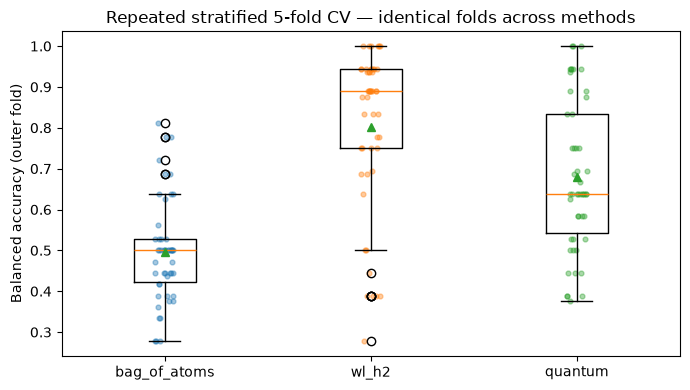

Paired differences versus bag-of-atoms (descriptive):


,method,mean_diff_vs_BoA,sd_diff,q02.5,q97.5
0,wl_h2,0.305,0.203,-0.099,0.642
1,quantum,0.184,0.239,-0.302,0.599



Quantum minus WL:
mean=-0.121, sd=0.257, q02.5=-0.586, q97.5=0.372


In [ ]:

names = list(results.keys())
scores = [results[n]["balanced_accuracy"] for n in names]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(scores, tick_labels=names, showmeans=True)
rng = np.random.default_rng(123)
for i, s in enumerate(scores, start=1):
    ax.scatter(
        np.full(len(s), i) + rng.uniform(-0.05, 0.05, len(s)),
        s, alpha=0.4, s=12
    )
ax.set_ylabel("Balanced accuracy (outer fold)")
ax.set_title("Repeated stratified 5-fold CV — identical folds across methods")
plt.tight_layout()
plt.show()

baseline = results["bag_of_atoms"]["balanced_accuracy"]
rows = []
for name in names:
    if name == "bag_of_atoms":
        continue
    diff = results[name]["balanced_accuracy"] - baseline
    rows.append({
        "method": name,
        "mean_diff_vs_BoA": np.mean(diff),
        "sd_diff": np.std(diff, ddof=1),
        "q02.5": np.quantile(diff, 0.025),
        "q97.5": np.quantile(diff, 0.975),
    })

paired_summary = pd.DataFrame(rows)
print("Paired differences versus bag-of-atoms (descriptive):")
display(paired_summary.round(3))

diff_q_wl = results["quantum"]["balanced_accuracy"] - results["wl_h2"]["balanced_accuracy"]
print("\nQuantum minus WL:")
print(
    f"mean={diff_q_wl.mean():.3f}, sd={diff_q_wl.std(ddof=1):.3f}, "
    f"q02.5={np.quantile(diff_q_wl, 0.025):.3f}, "
    f"q97.5={np.quantile(diff_q_wl, 0.975):.3f}"
)


In [ ]:
# bag_of_atoms | bal-acc 0.497 ± 0.126 | ROC-AUC 0.480 ± 0.243 (valid folds=50)
# wl_h2 | bal-acc 0.802 ± 0.197 | ROC-AUC 0.868 ± 0.161 (valid folds=50)
# quantum | bal-acc 0.681 ± 0.184 | ROC-AUC 0.775 ± 0.194 (valid folds=50)


## 9. Summary and interpretation

### Metrics we trust

**Primary:** balanced accuracy, reported across the repeated outer folds.

**Secondary:** ROC-AUC, with the number of valid folds reported. It is useful as a ranking diagnostic but has high uncertainty because each fold contains very few positive molecules.

**Not trusted as a primary conclusion:** ordinary accuracy

### Recommendation

The QEK model does not clearly outperform the classical graph kernel. The evidence from this 53-molecule benchmark would not by itself justify claiming a quantum advantage.

The most useful follow-up is to repeat the same leakage-safe protocol on a much larger dataset.
